# Bài 5 (Trang 29): Gom cụm khối u lành tính (benign) và ác tính (malignant)
**Họ tên:** Trần Minh Tấn - **MSSV:** 6451071071

Bộ dữ liệu: Breast Cancer Wisconsin (Diagnostic) - thuật toán: K-Means

## 1. Đọc dữ liệu từ Google Drive (file zip)

In [1]:
import zipfile, os, urllib.request
import pandas as pd
import numpy as np

file_id = "13qn-5-ccmFiPv4oPxcLxFol1KvRzk-L5"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

# Tải file zip từ Drive
if not zipfile.is_zipfile("wdbc.zip") if os.path.exists("wdbc.zip") else True:
    try:
        urllib.request.urlretrieve(url, "wdbc.zip")
    except Exception as e:
        print("Tải bằng urllib lỗi, thử gdown...", e)
    if not (os.path.exists("wdbc.zip") and zipfile.is_zipfile("wdbc.zip")):
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"])
        import gdown
        gdown.download(id=file_id, output="wdbc.zip", quiet=False)

# Giải nén
with zipfile.ZipFile("wdbc.zip") as z:
    print("Các file trong zip:", z.namelist())
    z.extractall("wdbc")

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Đã tải và giải nén file zip thành công")

Các file trong zip: ['wdbc.data', 'wdbc.names']
Họ tên: Trần Minh Tấn - MSSV: 6451071071
Đã tải và giải nén file zip thành công


In [2]:
# wdbc.data không có dòng tiêu đề -> tự đặt tên cột
base = ["radius", "texture", "perimeter", "area", "smoothness",
        "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
columns = ["ID", "Diagnosis"] \
          + [b + "_mean" for b in base] \
          + [b + "_se" for b in base] \
          + [b + "_worst" for b in base]

data = pd.read_csv("wdbc/wdbc.data", header=None, names=columns)

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Kích thước dữ liệu (dòng, cột):", data.shape)
print("\n5 dòng đầu tiên:")
print(data.head())

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Kích thước dữ liệu (dòng, cột): (569, 32)

5 dòng đầu tiên:
         ID Diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave_points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280   

## 2. Khảo sát và tiền xử lý dữ liệu

In [3]:
print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Số lượng khối u theo chẩn đoán (M = ác tính, B = lành tính):")
print(data["Diagnosis"].value_counts())

print("\nSố giá trị thiếu:", data.isnull().sum().sum())
print("\nThống kê mô tả (5 cột đầu đặc trưng):")
print(data.iloc[:, 2:7].describe())

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Số lượng khối u theo chẩn đoán (M = ác tính, B = lành tính):
Diagnosis
B    357
M    212
Name: count, dtype: int64

Số giá trị thiếu: 0

Thống kê mô tả (5 cột đầu đặc trưng):
       radius_mean  texture_mean  perimeter_mean    area_mean  smoothness_mean
count   569.000000    569.000000      569.000000   569.000000       569.000000
mean     14.127292     19.289649       91.969033   654.889104         0.096360
std       3.524049      4.301036       24.298981   351.914129         0.014064
min       6.981000      9.710000       43.790000   143.500000         0.052630
25%      11.700000     16.170000       75.170000   420.300000         0.086370
50%      13.370000     18.840000       86.240000   551.100000         0.095870
75%      15.780000     21.800000      104.100000   782.700000         0.105300
max      28.110000     39.280000      188.500000  2501.000000         0.163400


In [4]:
from sklearn.preprocessing import StandardScaler

# Bỏ ID và nhãn chẩn đoán (gom cụm là học không giám sát)
X = data.drop(columns=["ID", "Diagnosis"])
y_true = (data["Diagnosis"] == "M").astype(int)   # M = 1 (ác tính), B = 0 (lành tính)

# Chuẩn hóa dữ liệu (đưa các đặc trưng về cùng thang đo)
X_scaled = StandardScaler().fit_transform(X)

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Kích thước dữ liệu sau chuẩn hóa:", X_scaled.shape)

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Kích thước dữ liệu sau chuẩn hóa: (569, 30)


## 3. Chọn số cụm (Elbow method)

Họ tên: Trần Minh Tấn - MSSV: 6451071071


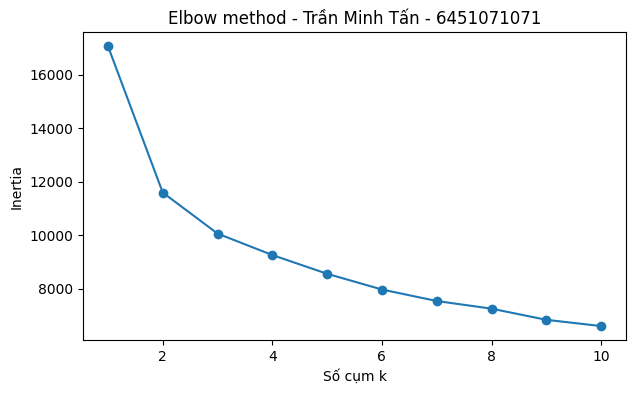

In [5]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertia = []
K_range = range(1, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
plt.figure(figsize=(7, 4))
plt.plot(list(K_range), inertia, marker="o")
plt.xlabel("Số cụm k")
plt.ylabel("Inertia")
plt.title("Elbow method - Trần Minh Tấn - 6451071071")
plt.show()

## 4. Gom cụm bằng K-Means (k = 2: lành tính / ác tính)

In [6]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Số mẫu trong mỗi cụm:")
print(pd.Series(clusters).value_counts().sort_index())

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Số mẫu trong mỗi cụm:
0    375
1    194
Name: count, dtype: int64


## 5. Đánh giá kết quả gom cụm so với nhãn thật

In [7]:
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             silhouette_score, adjusted_rand_score)

# Gán nhãn cụm cho khớp nhãn thật (cụm nào nhiều ác tính hơn -> ác tính)
y_pred = clusters.copy()
if accuracy_score(y_true, y_pred) < 0.5:
    y_pred = 1 - y_pred

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Ma trận nhầm lẫn (hàng: thật B/M, cột: dự đoán B/M):")
print(pd.DataFrame(confusion_matrix(y_true, y_pred),
                   index=["Thật: Lành tính (B)", "Thật: Ác tính (M)"],
                   columns=["Cụm: Lành tính", "Cụm: Ác tính"]))
print(f"\nĐộ chính xác của việc gom cụm: {accuracy_score(y_true, y_pred):.4f}")
print(f"Silhouette score             : {silhouette_score(X_scaled, clusters):.4f}")
print(f"Adjusted Rand Index          : {adjusted_rand_score(y_true, clusters):.4f}")

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Ma trận nhầm lẫn (hàng: thật B/M, cột: dự đoán B/M):
                     Cụm: Lành tính  Cụm: Ác tính
Thật: Lành tính (B)             339            18
Thật: Ác tính (M)                36           176

Độ chính xác của việc gom cụm: 0.9051
Silhouette score             : 0.3434
Adjusted Rand Index          : 0.6536


## 6. Trực quan hóa kết quả (PCA giảm về 2 chiều)

Họ tên: Trần Minh Tấn - MSSV: 6451071071


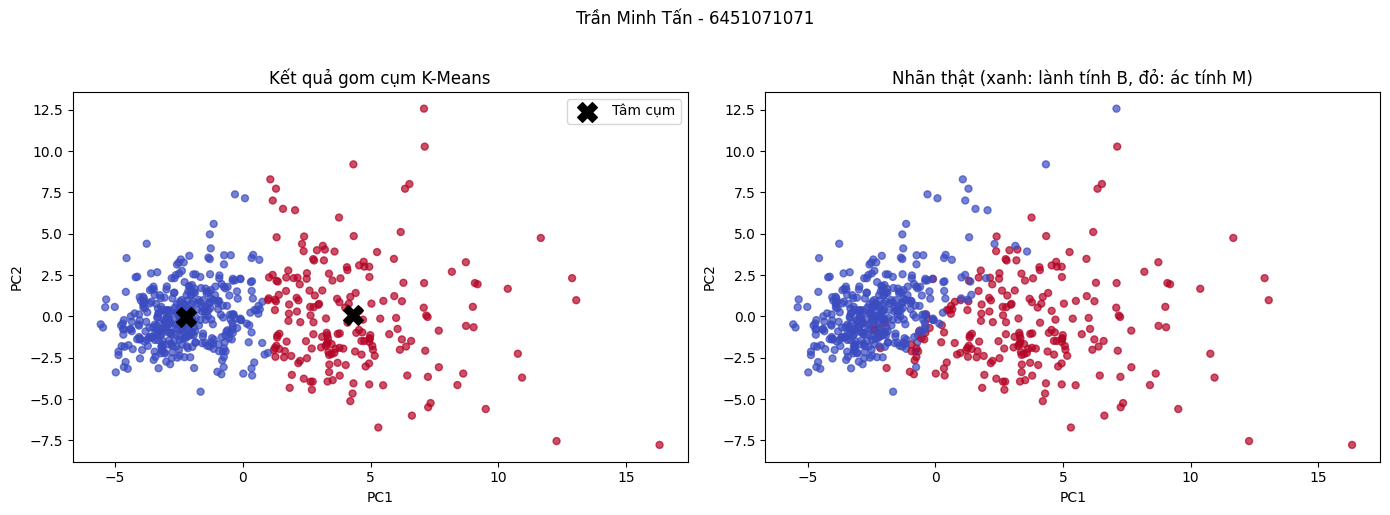

In [8]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centers_pca = pca.transform(kmeans.cluster_centers_)

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_pred, cmap="coolwarm", s=25, alpha=0.7)
axes[0].scatter(centers_pca[:, 0], centers_pca[:, 1], c="black", marker="X", s=200, label="Tâm cụm")
axes[0].set_title("Kết quả gom cụm K-Means")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].legend()

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap="coolwarm", s=25, alpha=0.7)
axes[1].set_title("Nhãn thật (xanh: lành tính B, đỏ: ác tính M)")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")

plt.suptitle("Trần Minh Tấn - 6451071071", y=1.02)
plt.tight_layout()
plt.show()

## 7. Nhận xét
- K-Means với k = 2 chia các khối u thành 2 nhóm: lành tính (benign) và ác tính (malignant).
- Kết quả gom cụm được so sánh với nhãn chẩn đoán thật (M/B) qua ma trận nhầm lẫn, độ chính xác, Silhouette score và Adjusted Rand Index.
- Biểu đồ PCA cho thấy hai nhóm khối u tách biệt khá rõ trên không gian 2 chiều.